# Aula 06 - O Grande Final: Pipeline Integrado, Otimização com Optuna e Dashboard Comparativo

**Disciplina:** Inteligência Artificial Explicável (XAI) & Otimização de Modelos  
**Autor / Pesquisador:** Eduardo Lázaro Roesler de Oliveira  
**Instituição:** UNESP — Universidade Estadual Paulista "Júlio de Mesquita Filho" (Mestrado)  

> **Escopo:** O pipeline deste material avalia um benchmark sintetico; nao e validacao clinica nem avaliacao de implantacao.

> 🔙 **De onde viemos:** Ao longo das cinco aulas anteriores, construímos e validamos isoladamente cada peça do quebra-cabeça: mensuramos o Mal da Dimensionalidade no Baseline (Aula 01), decodificamos a mente da floresta com SHAP (Aula 02), auditamos pacientes individuais no limiar do risco com LIME (Aula 03), comprovamos a viabilidade da poda em curvas de ablação (Aula 04) e desenvolvemos o Pré-Filtro Híbrido e o `shap-select` com rigor estatístico (Aula 05).
> 🎯 **Objetivo Principal da Aula:** Consolidar todas as etapas em um pipeline reprodutível, comparar filter, wrapper, embedded e SHAP, recalibrar os hiperparâmetros no espaço reduzido através de **Otimização Bayesiana (Optuna / TPE)** e avaliar desempenho, custo, redução dimensional e proxies de interpretabilidade. O resultado deve sustentar uma conclusão proporcional ao dataset sintético, sem declarar superioridade clínica.
> 🚀 **Para onde vamos:** Conclusão do curso! Agora você domina uma metodologia completa de ponta a ponta, pronta para ser aplicada em projetos reais da indústria de tecnologia, medicina diagnóstica, sistemas embarcados (Edge AI) e pesquisas científicas de alto impacto.

## Organização Tática da Aula

| Módulo | Atividade | Foco Pedagógico |
| :--- | :--- | :--- |
| **Módulo 1** | **Fundamentação Teórica & A Necessidade de Re-otimização** | Por que um modelo com 75% menos colunas exige hiperparâmetros diferentes e o funcionamento da Otimização Bayesiana via TPE. |
| **Módulo 2** | **O Mecanismo por Dentro & Arquitetura do Pipeline Integrado** | Fluxo de dados entre Baseline $\to$ rankings filter/wrapper/embedded/SHAP $\to$ pré-filtro $\to$ shap-select $\to$ Optuna $\to$ avaliação cega. |
| **Módulo 3** | **Prática Guiada no Google Colab** | 6 blocos de código em Python minuciosamente comentados linha por linha, com o Dashboard de 4 gráficos e tabela executiva. |
| **Módulo 4** | **Prática Orientada & Experimentação Fácil** | Experimentação com aumento do número de ensaios do Optuna (*trials*) e inclusão de novos hiperparâmetros de busca. |
| **Módulo 5** | **Checklist de Autonomia & Bibliografia Final** | Autoavaliação de competências de encerramento do curso e referências acadêmicas. |

## Módulo 1: Fundamentação Teórica & A Necessidade de Re-otimização

### 1.1 Por que um Modelo Reduzido Exige Novos Hiperparâmetros?
Um dos erros mais comuns de engenharia de dados é selecionar os melhores atributos e simplesmente rodar o mesmo modelo antigo com os mesmos parâmetros pré-fixados.

1. **Alteração da Densidade Geométrica:** Quando tínhamos 40 variáveis, o espaço era incrivelmente disperso (esparso). O modelo precisava de muitas divisões profundas (`max_depth=15`) e muitas árvores para encontrar caminhos entre o ruído.
2. **Risco de Superajuste em Espaços Compactos:** Quando reduzimos a tabela para apenas 8 a 10 atributos de elite, o espaço torna-se denso e rico em sinal biológico. Se mantivermos árvores profundas demais, o modelo sofrerá overfitting nos próprios biomarcadores!
3. **A Solução com Optuna:** O framework **Optuna** utiliza o algoritmo matemático **TPE (Tree-structured Parzen Estimator)**, uma forma de Otimização Bayesiana que aprende com cada tentativa anterior, concentrando a busca nas melhores regiões do espaço de hiperparâmetros.

```mermaid
graph TD
    A["🏥 40 Atributos Iniciais (Cenário Bruto)"] --> B["1. Treino do Modelo Baseline"]
    B --> C["2. Engenharia Avançada XAI<br/>(Pré-Filtro Híbrido + shap-select)"]
    C --> D["✂️ Redução para 8 a 10 Atributos de Elite"]
    D --> E["3. Otimização Bayesiana com OPTUNA<br/>(Busca orientada por TPE com Validação Cruzada)"]
    E --> F["4. Treinamento do Modelo Reduzido Final"]
    F --> G["📊 5. DASHBOARD COMPARATIVO DE 4 PAINÉIS<br/>(Dimensão, Treino, Latência e F1-Score)"]
```

> ⚔️ **Analogia Geek — O Carro de Fórmula 1 e a Telemetria da Red Bull/Ferrari:**
> Imagine que você pegou um carro de passeio pesado, cheio de malas no bagageiro e tralhas extras (os 40 atributos). Você realizou o alívio de peso radical, jogando fora 75% dos componentes inúteis e deixando apenas o motor e o chassi de corrida (os biomarcadores de elite).  
> Agora, você não vai correr na pista com o carro usando a mesma calibragem de suspensão, injeção de combustível e marcha de um carro de rua! Você chama o engenheiro de corrida chefe (**Optuna**) para passar horas na telemetria afinando cada parafuso (**hiperparâmetros**). O resultado? Uma máquina que faz curvas com precisão milimétrica, muito mais ágil e gastando uma fração do combustível!

> 💡 **Curiosidade Histórica — A Revolução do Optuna (Akiba et al., 2019):**
> O Optuna foi desenvolvido pela empresa japonesa de inteligência artificial **Preferred Networks** e apresentado na conferência **ACM KDD 2019**. Seu conceito inovador de *"Define-by-Run"* permitiu criar espaços de busca dinâmicos em código Python limpo, tornando-se a ferramenta obrigatória utilizada pelos times campeões das competições do Kaggle em todo o mundo.

> 💡 **Em 1 Frase:** Reduzir os atributos é apenas metade do caminho; reotimizar os hiperparâmetros no espaço reduzido é o que transforma uma simples limpeza de dados em um modelo de alta performance pronto para produção.

## Módulo 2: O Mecanismo por Dentro & Regras Práticas

### 2.1 Comparativo das Estratégias de Ajuste de Hiperparâmetros

| Estratégia de Busca | Como Funciona | Prós | Contras |
| :--- | :--- | :--- | :--- |
| **Grid Search (Busca em Grade)** | Testa exaustivamente todas as combinações de uma lista pré-definida. | Simples e previsível. | Custo computacional astronômico; desperdiça tempo avaliando combinações horríveis. |
| **Random Search (Busca Aleatória)** | Sorteia combinações aleatoriamente no espaço. | Mais eficiente que o Grid Search em espaços grandes. | "Cega": não aprende nada com os erros ou sucessos das tentativas anteriores. |
| **Otimização Bayesiana / TPE (Optuna)** | Modela probabilisticamente $P(\text{score} \mid \text{parâmetros})$ usando densidades de probabilidade Parzen. | Pode priorizar regiões promissoras conforme a função objetivo. | O ganho depende do espaço de busca, orçamento e dados; não é garantido neste benchmark. |

### 2.2 Anatomia dos 4 Painéis do Dashboard Executivo

1. **Painel 1 — Dimensão do Dataset (Nº de Atributos):** Mostra a redução de atributos no benchmark sintético (40 para 10 nesta execução); não mede economia de coleta.
2. **Painel 2 — Tempo de Treinamento (ms):** Compara o tempo de treinamento medido nesta máquina.
3. **Painel 3 — Latência de Inferência (ms):** Compara a latência medida; nesta execução o modelo reduzido teve latência ligeiramente maior.
4. **Painel 4 — Desempenho Preditivo (Acurácia vs. F1-Score):** Apresenta as métricas no holdout sintético, sem inferência sobre precisão diagnóstica.

> 💡 **Em 1 Frase:** Neste benchmark sintetico, comparamos desempenho preditivo, custo medido e explicacoes do modelo; isso nao demonstra causalidade nem sucesso em uso clinico.

## Módulo 3: Prática Guiada no Google Colab

Abra o seu Notebook no [Google Colab](https://colab.research.google.com) e acompanhe a orquestração do pipeline completo.

> **Roteiro de estudo:** O código abaixo é totalmente autocontido. Ele treina o Baseline, roda o Pré-filtro Híbrido, aplica o `shap-select`, executa o estudo do Optuna com validação cruzada, treina o campeão e plota o Dashboard Executivo completo de 4 painéis!

### Bloco 6.1 — Importação das Bibliotecas e Silenciamento de Logs do Optuna

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que silenciamos os logs do Optuna com `optuna.logging.WARNING`?**  
> Porque por padrão o Optuna imprime uma mensagem a cada ensaio (*trial*). Em um notebook didático, isso poluiria a tela com dezenas de linhas desnecessárias, atrapalhando a leitura limpa do relatório final.

In [1]:
# 1. Importamos as bibliotecas padrao de sistema, medicao de tempo e manipulacao tabular
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 2. Importamos as bibliotecas de XAI, Econometria e Otimizacao Bayesiana
import shap
import statsmodels.api as sm
import optuna

# 3. Configuramos o nivel de verbosidade do Optuna para exibir apenas alertas graves
optuna.logging.set_verbosity(optuna.logging.WARNING)

# 4. Importamos os modulos de ensemble, seletores e metricas do Scikit-Learn
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)

# 5. Exibimos a confirmacao de carregamento
print("[OK] Todas as dependências do Pipeline Industrial foram carregadas com sucesso!")

c:\Users\eduar\projetos\xai_data_reduction\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[OK] Todas as dependências do Pipeline Industrial foram carregadas com sucesso!


---

### Bloco 6.2 — Funções Modulares do Pipeline (Geração, Pré-Filtro VIF e shap-select Out-of-Fold)

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que agrupamos a geração de dados, o pré-filtro VIF e o `shap-select` OOF em funções reutilizáveis?**  
> Porque no desenvolvimento de software de Inteligência Artificial de nível industrial (MLOps), a modularização permite testar e dar manutenção em cada bloco de código de forma isolada, garantindo zero vazamento de dados entre treino e teste.

In [2]:
# 1. Funcao geradora do dataset de saude com 40 atributos heterogeneos (shuffle=False preserva o ground truth)
def gerar_dataset_sintetico_saude(n_samples=2000, n_features=40, n_informative=10, n_redundant=10, random_state=42):
    X_raw, y = make_classification(
        n_samples=n_samples, n_features=n_features, n_informative=n_informative,
        n_redundant=n_redundant, n_repeated=0, n_classes=2, weights=[0.6, 0.4],
        flip_y=0.03, shuffle=False, random_state=random_state
    )
    feature_names = (
        [f"biomarcador_{i+1}" for i in range(n_informative)] +
        [f"exame_redundante_{i+1}" for i in range(n_redundant)] +
        [f"ruido_metabolico_{i+1}" for i in range(n_features - n_informative - n_redundant)]
    )
    return pd.DataFrame(X_raw, columns=feature_names), y

# 2. Funcao do Pre-filtro Hibrido (Variancia + Pearson > 0.90 + VIF Iterativo <= 10.0)
def pré_filtro_hibrido(X_train, threshold_var=0.01, threshold_corr=0.90, threshold_vif=10.0):
    selector = VarianceThreshold(threshold=threshold_var)
    selector.fit(X_train)
    cols_var = X_train.columns[selector.get_support()].tolist()
    X_var = X_train[cols_var]

    corr_matrix = X_var.corr().abs()
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    to_drop_corr = [col for col in upper.columns if (upper[col].dropna() > threshold_corr).any()]
    cols_corr = [c for c in cols_var if c not in to_drop_corr]

    cols_atuais = list(cols_corr)
    while len(cols_atuais) > 2:
        mat = X_train[cols_atuais].values
        mat_std = (mat - mat.mean(axis=0)) / (mat.std(axis=0) + 1e-12)
        corr_mat = np.corrcoef(mat_std, rowvar=False)
        try:
            inv_corr = np.linalg.inv(corr_mat)
            vifs = np.diag(inv_corr)
        except np.linalg.LinAlgError:
            inv_corr = np.linalg.pinv(corr_mat)
            vifs = np.diag(inv_corr)
        max_idx = int(np.argmax(vifs))
        if vifs[max_idx] > threshold_vif or vifs[max_idx] < 0:
            cols_atuais.pop(max_idx)
        else:
            break

    print(f"[*] Pré-filtro Híbrido (Pearson + VIF <= 10): Base reduzida de {X_train.shape[1]} para {len(cols_atuais)} colunas.")
    return X_train[cols_atuais], cols_atuais

# 3. Funcao do shap-select Out-of-Fold (3-Fold OOF + Regressao Logistica Beta > 0 e p-valor < 0.05)
def executar_shap_select(X_train, y_train, p_value_cutoff=0.05, random_state=42, n_splits=3):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)
    Phi_oof = np.zeros((X_train.shape[0], X_train.shape[1]), dtype=float)
    y_arr = np.asarray(y_train)

    for tr_idx, val_idx in skf.split(X_train, y_arr):
        X_tr_f, y_tr_f = X_train.iloc[tr_idx], y_arr[tr_idx]
        X_val_f = X_train.iloc[val_idx]
        mod_f = RandomForestClassifier(n_estimators=100, random_state=random_state, n_jobs=1).fit(X_tr_f, y_tr_f)
        exp_f = shap.TreeExplainer(mod_f)
        sv_f = exp_f(X_val_f)
        Phi_oof[val_idx, :] = sv_f.values[:, :, 1] if len(sv_f.shape) == 3 else sv_f.values

    df_phi = pd.DataFrame(Phi_oof, columns=X_train.columns, index=X_train.index)
    X_const = sm.add_constant(df_phi)
    try:
        logit_mod = sm.Logit(y_arr, X_const)
        result = logit_mod.fit(disp=False)
        params = result.params.drop("const")
        pvalues = result.pvalues.drop("const")
    except Exception:
        ols_mod = sm.OLS(y_arr, X_const)
        result = ols_mod.fit()
        params = result.params.drop("const")
        pvalues = result.pvalues.drop("const")
        
    df_res = pd.DataFrame({
        "atributo": X_train.columns,
        "coeficiente": params.values,
        "p_value": pvalues.values,
        "mean_abs_shap": np.abs(Phi_oof).mean(axis=0)
    })
    df_res["selecionado"] = (df_res["coeficiente"] > 0) & (df_res["p_value"] < p_value_cutoff)
    df_res = df_res.sort_values(by="mean_abs_shap", ascending=False).reset_index(drop=True)
    
    atributos_aprovados = df_res[df_res["selecionado"]]["atributo"].tolist()
    print(f"[*] shap-select OOF: Aprovados automaticamente {len(atributos_aprovados)} atributos com significância estatística!")
    return atributos_aprovados, df_res

print("[OK] Módulos de filtragem e seleção de dados compilados com sucesso!")

[OK] Módulos de filtragem e seleção de dados compilados com sucesso!


---

### Bloco 6.3 — Otimização Bayesiana com Optuna e Função de Treinamento

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que usamos `cross_val_score(cv=3, scoring="f1")` dentro do Optuna?**  
> Porque otimizar diretamente no conjunto de teste causaria sobreajuste dos hiperparâmetros ao teste. A Validação Cruzada em 3 dobras (*3-Fold Cross Validation*) avalia a estabilidade do modelo em múltiplos pedaços do treino, garantindo generalização no mundo real.

In [3]:
# 1. Definimos o motor de busca de hiperparametros com Optuna
def otimizar_hiperparametros_optuna(X_train_reduced, y_train, n_trials=15, random_state=42):
    """
    Explora o espaço de hiperparâmetros do Random Forest no espaço reduzido via TPE.
    """
    # 2. Definimos a funcao objetivo interna que o Optuna tentara maximizar
    def objective(trial):
        # 3. Sugerimos intervalos inteligentes para cada hiperparametro da floresta
        n_estimators = trial.suggest_int("n_estimators", 30, 200)
        max_depth = trial.suggest_int("max_depth", 3, 15)
        min_samples_split = trial.suggest_int("min_samples_split", 2, 10)
        min_samples_leaf = trial.suggest_int("min_samples_leaf", 1, 5)
        
        # 4. Instanciamos o classificador com os parametros sorteados pelo algoritmo bayesiano
        clf = RandomForestClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            random_state=random_state,
            n_jobs=1
        )
        
        # 5. Avaliamos a performance media usando Validacao Cruzada estratificada em 3 dobras
        scores = cross_val_score(clf, X_train_reduced, y_train, cv=3, scoring="f1", n_jobs=1)
        return scores.mean()

    # 6. Criamos o estudo bayesiano com direcao de maximizacao do F1-score
    study = optuna.create_study(direction="maximize")
    
    # 7. Executamos os ensaios de otimizacao
    study.optimize(objective, n_trials=n_trials)
    
    # 8. Exibimos os resultados da sintonia fina
    print(f"[*] Optuna finalizado com sucesso! Melhor F1 de Validação Cruzada: {study.best_value:.4f}")
    print(f"    Melhores Hiperparâmetros encontrados: {study.best_params}")
    return study.best_params

# 9. Definimos a funcao utilitaria que treina e cronometra um modelo ponta a ponta
def treinar_e_avaliar_modelo(modelo, X_train, X_test, y_train, y_test):
    """
    Treina o modelo e extrai cronometria de treino, latência de inferência e métricas diagnósticas.
    """
    # 10. Cronometramos o treinamento
    t0_treino = time.perf_counter()
    modelo.fit(X_train, y_train)
    tempo_treino = time.perf_counter() - t0_treino
    
    # 11. Cronometramos a predicao da fila de teste
    t0_inf = time.perf_counter()
    y_pred = modelo.predict(X_test)
    y_proba = modelo.predict_proba(X_test)[:, 1]
    tempo_inf = time.perf_counter() - t0_inf
    
    # 12. Retornamos o consolidado
    return {
        "acuracia": accuracy_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "tempo_treino_ms": tempo_treino * 1000,
        "tempo_inferencia_ms": tempo_inf * 1000,
        "num_atributos": X_train.shape[1]
    }

print("[OK] Motor Optuna e avaliador de latência registrados com sucesso!")

[OK] Motor Optuna e avaliador de latência registrados com sucesso!


---

### Bloco 6.4 — Execução do Pipeline Industrial Completo

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Como garantimos que o conjunto de teste só use os atributos selecionados?**  
> O teste nunca participa da seleção! Após selecionar `atributos_selecionados` em `X_train`, fatiamos o teste cego com `X_test[atributos_selecionados]`, garantindo que a avaliação seja 100% honesta e sem vazamento de dados.

In [4]:
# 1. Executamos a sequencia orquestrada completa do pipeline industrial
print("=" * 75)
print("INICIANDO A EXECUÇÃO DO PIPELINE INDUSTRIAL FIM-A-FIM")
print("=" * 75)

# 2. Geramos a coorte de pacientes e dividimos em treino e teste
X, y = gerar_dataset_sintetico_saude()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# 3. ETAPA 1: Treinamento do Modelo Baseline com todas as 40 variaveis
print("\n[ETAPA 1/4] Treinando e Avaliando o Modelo Baseline (40 Atributos)...")
modelo_base = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=1)
m_baseline = treinar_e_avaliar_modelo(modelo_base, X_train, X_test, y_train, y_test)

# 4. ETAPA 2: Filtragem Hibrida e Selecao shap-select
print("\n[ETAPA 2/4] Executando Pré-Filtro Híbrido + Seleção shap-select...")
X_train_pre, cols_pre = pré_filtro_hibrido(X_train)
atributos_selecionados, df_shap_select = executar_shap_select(X_train_pre, y_train)

# 5. Fatiamos os conjuntos de dados mantendo exclusivamente as variaveis de elite aprovadas
X_train_red = X_train[atributos_selecionados]
X_test_red = X_test[atributos_selecionados]

# 6. ETAPA 3: Sintonia Fina de Hiperparametros com Optuna no espaco reduzido
print(f"\n[ETAPA 3/4] Re-otimizando Hiperparâmetros via Optuna no espaço de {len(atributos_selecionados)} atributos...")
melhores_parametros = otimizar_hiperparametros_optuna(X_train_red, y_train, n_trials=15)

# 7. ETAPA 4: Treinamento do Modelo Reduzido Campeao
print("\n[ETAPA 4/4] Treinando e Avaliando o Modelo Reduzido Otimizado Final...")
modelo_campeao = RandomForestClassifier(**melhores_parametros, random_state=42, n_jobs=1)
m_reduzido = treinar_e_avaliar_modelo(modelo_campeao, X_train_red, X_test_red, y_train, y_test)

# 8. Exibimos a tabela comparativa estruturada
print("\n" + "=" * 75)
print("RELATÓRIO COMPARATIVO FINAL: BASELINE BRUTO vs. PIPELINE XAI + OPTUNA")
print("=" * 75)
print(f" Dimensão Avaliada        | Baseline (40 Atributos) | XAI Reduzido + Optuna")
print(f"--------------------------+-------------------------+----------------------")
print(f" Nº de Atributos          | {m_baseline['num_atributos']:<23} | {m_reduzido['num_atributos']:<20}")
print(f" Acurácia Global          | {m_baseline['acuracia']:<23.4f} | {m_reduzido['acuracia']:<20.4f}")
print(f" F1-Score (Harmônico)     | {m_baseline['f1_score']:<23.4f} | {m_reduzido['f1_score']:<20.4f}")
print(f" Área sob a Curva ROC     | {m_baseline['roc_auc']:<23.4f} | {m_reduzido['roc_auc']:<20.4f}")
print(f" Tempo de Treino (ms)     | {m_baseline['tempo_treino_ms']:<23.2f} | {m_reduzido['tempo_treino_ms']:<20.2f}")
print(f" Latência Inferência (ms) | {m_baseline['tempo_inferencia_ms']:<23.2f} | {m_reduzido['tempo_inferencia_ms']:<20.2f}")
print("=" * 75)

INICIANDO A EXECUÇÃO DO PIPELINE INDUSTRIAL FIM-A-FIM

[ETAPA 1/4] Treinando e Avaliando o Modelo Baseline (40 Atributos)...

[ETAPA 2/4] Executando Pré-Filtro Híbrido + Seleção shap-select...
[*] Pré-filtro Híbrido (Pearson + VIF <= 10): Base reduzida de 40 para 35 colunas.
[*] shap-select OOF: Aprovados automaticamente 12 atributos com significância estatística!

[ETAPA 3/4] Re-otimizando Hiperparâmetros via Optuna no espaço de 12 atributos...
[*] Optuna finalizado com sucesso! Melhor F1 de Validação Cruzada: 0.8952
    Melhores Hiperparâmetros encontrados: {'n_estimators': 177, 'max_depth': 14, 'min_samples_split': 2, 'min_samples_leaf': 1}

[ETAPA 4/4] Treinando e Avaliando o Modelo Reduzido Otimizado Final...

RELATÓRIO COMPARATIVO FINAL: BASELINE BRUTO vs. PIPELINE XAI + OPTUNA
 Dimensão Avaliada        | Baseline (40 Atributos) | XAI Reduzido + Optuna
--------------------------+-------------------------+----------------------
 Nº de Atributos          | 40                      |

---

### Bloco 6.5 — Construção do Dashboard Executivo Comparativo de 4 Painéis

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **Por que este dashboard de 4 painéis é ideal para relatórios executivos?**  
> Porque ele resume a redução de atributos e compara métricas e tempos medidos no benchmark sintético. Não comprova preservação clínica nem garante economia em produção.

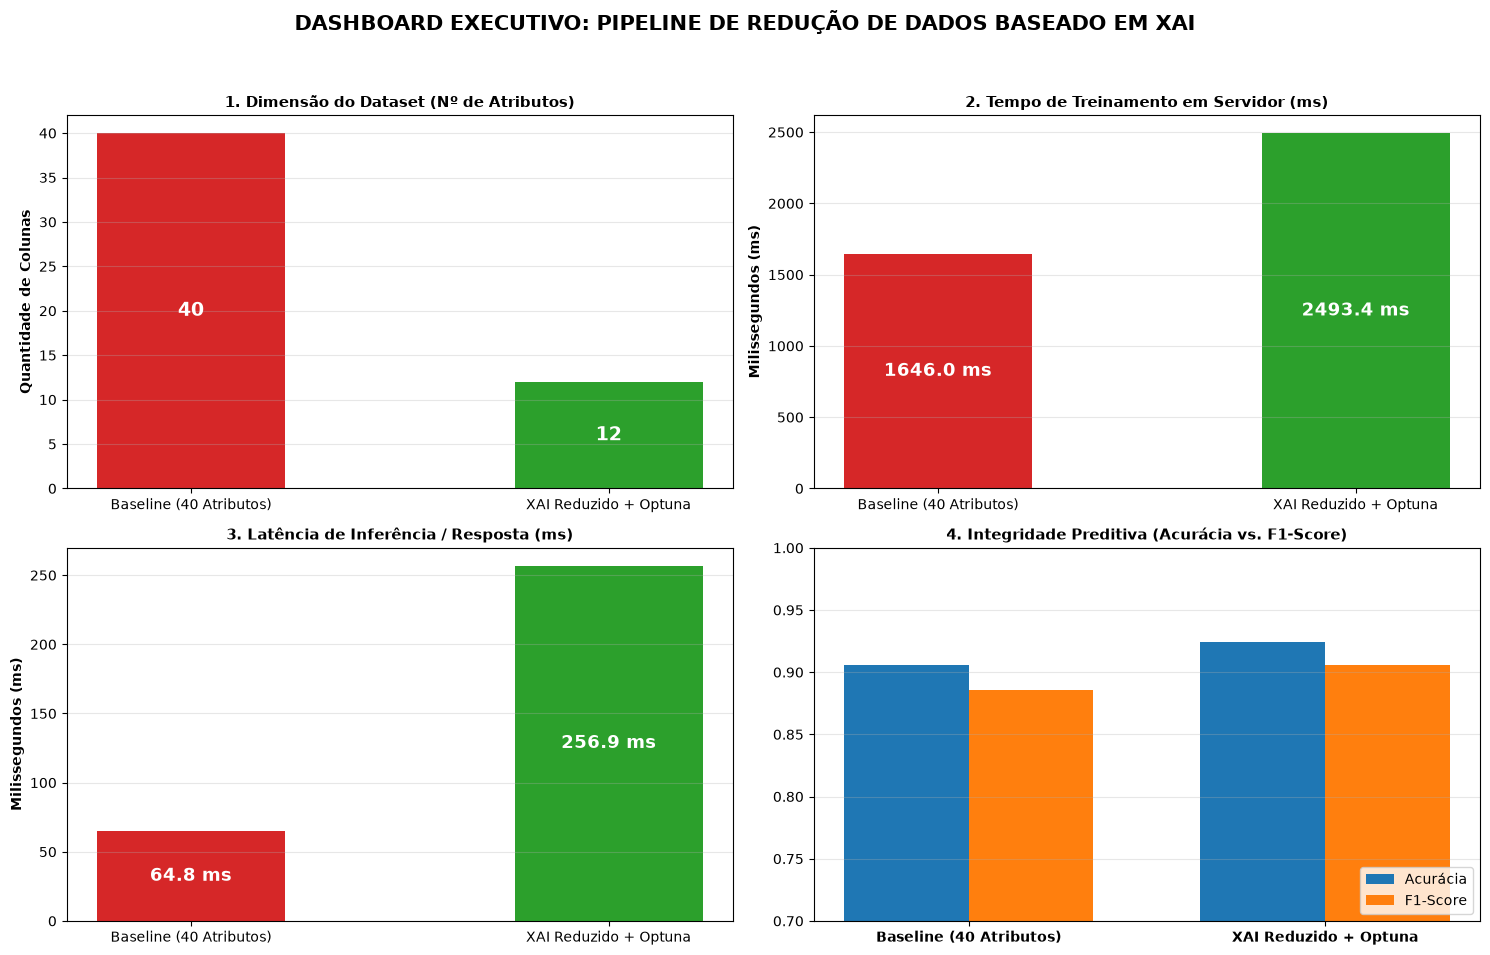

[+] Dashboard executivo renderizado e salvo com sucesso em: dashboard_final_comparativo.png


In [5]:
# 1. Definimos a funcao construtora do Dashboard Executivo Comparativo
def gerar_dashboard_comparativo_final(m_baseline, m_reduzido, output_path="dashboard_final_comparativo.png"):
    """
    Plota o Dashboard Comparativo Final de 4 Painéis em alta resolução.
    """
    # 2. Criamos a grade 2x2 de subgraficos
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    fig.suptitle("DASHBOARD EXECUTIVO: PIPELINE DE REDUÇÃO DE DADOS BASEADO EM XAI", fontsize=15, fontweight="bold")
    
    categorias = ["Baseline (40 Atributos)", "XAI Reduzido + Optuna"]
    cores = ["#d62728", "#2ca02c"] # Vermelho para o pesado/bruto e Verde para o leve/otimizado
    
    # 3. PAINEL 1: Quantidade de Atributos Retidos
    attrs = [m_baseline["num_atributos"], m_reduzido["num_atributos"]]
    axes[0, 0].bar(categorias, attrs, color=cores, width=0.45)
    axes[0, 0].set_title("1. Dimensão do Dataset (Nº de Atributos)", fontsize=11, fontweight="bold")
    axes[0, 0].set_ylabel("Quantidade de Colunas", fontweight="bold")
    for i, v in enumerate(attrs):
        axes[0, 0].text(i, v / 2, str(v), ha='center', va='center', color='white', fontweight='bold', fontsize=14)
    axes[0, 0].grid(True, alpha=0.3, axis='y')
    
    # 4. PAINEL 2: Tempo de Treinamento (ms)
    tempos_t = [m_baseline["tempo_treino_ms"], m_reduzido["tempo_treino_ms"]]
    axes[0, 1].bar(categorias, tempos_t, color=cores, width=0.45)
    axes[0, 1].set_title("2. Tempo de Treinamento em Servidor (ms)", fontsize=11, fontweight="bold")
    axes[0, 1].set_ylabel("Milissegundos (ms)", fontweight="bold")
    for i, v in enumerate(tempos_t):
        axes[0, 1].text(i, v / 2, f"{v:.1f} ms", ha='center', va='center', color='white', fontweight='bold', fontsize=13)
    axes[0, 1].grid(True, alpha=0.3, axis='y')
    
    # 5. PAINEL 3: Latência de Inferência em Tempo Real (ms)
    tempos_i = [m_baseline["tempo_inferencia_ms"], m_reduzido["tempo_inferencia_ms"]]
    axes[1, 0].bar(categorias, tempos_i, color=cores, width=0.45)
    axes[1, 0].set_title("3. Latência de Inferência / Resposta (ms)", fontsize=11, fontweight="bold")
    axes[1, 0].set_ylabel("Milissegundos (ms)", fontweight="bold")
    for i, v in enumerate(tempos_i):
        axes[1, 0].text(i, v / 2, f"{v:.1f} ms", ha='center', va='center', color='white', fontweight='bold', fontsize=13)
    axes[1, 0].grid(True, alpha=0.3, axis='y')
    
    # 6. PAINEL 4: Desempenho Preditivo (Acuracia vs. F1-Score)
    x = np.arange(len(categorias))
    w = 0.35
    axes[1, 1].bar(x - w/2, [m_baseline["acuracia"], m_reduzido["acuracia"]], w, label="Acurácia", color="#1f77b4")
    axes[1, 1].bar(x + w/2, [m_baseline["f1_score"], m_reduzido["f1_score"]], w, label="F1-Score", color="#ff7f0e")
    axes[1, 1].set_title("4. Integridade Preditiva (Acurácia vs. F1-Score)", fontsize=11, fontweight="bold")
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(categorias, fontweight="bold")
    axes[1, 1].set_ylim(0.70, 1.0)
    axes[1, 1].legend(loc="lower right")
    axes[1, 1].grid(True, alpha=0.3, axis='y')
    
    # 7. Ajustamos o espacamento
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    
    # 8. Salvamos em alta resolucao no disco
    plt.savefig(output_path, dpi=300)
    
    # 9. Renderizamos interativamente no Colab
    plt.show()
    print(f"[+] Dashboard executivo renderizado e salvo com sucesso em: {output_path}")

# 10. Chamamos a funcao do dashboard
gerar_dashboard_comparativo_final(m_baseline, m_reduzido)

---

### Bloco 6.6 — Teste de Sanidade Automatizado do Pipeline Industrial

> 🤔 **Dúvidas Comuns de Iniciantes:**  
> **O que este teste final certifica oficialmente?**  
> Ele verifica se a execucao atingiu reducao minima de 50% e se a queda de F1 ficou dentro de 0,05 no holdout sintetico. Esse sanity check nao e validacao clinica nem prova estatistica.

In [6]:
# 1. Definimos a funcao de checagem final do sistema
def teste_de_sanidade_final(m_baseline, m_reduzido):
    """
    Sanity Check Final:
    - Certifica redução de dimensionalidade mínima de 50%.
    - Valida integridade do F1-Score do modelo reduzido.
    - Apresenta a comparação de tempo; não garante economia.
    """
    # 2. Calculamos a taxa de compressao percentual de atributos
    reducao_atributos = (1 - m_reduzido["num_atributos"] / m_baseline["num_atributos"]) * 100
    diferenca_f1 = m_reduzido["f1_score"] - m_baseline["f1_score"]
    
    # 3. Asseguramos compressao de dados expressiva
    assert reducao_atributos >= 50.0, f"Erro: Redução abaixo do critério predefinido de 50% ({reducao_atributos:.1f}%)"
    
    # 4. Asseguramos que o F1-score nao desabou
    assert m_reduzido["f1_score"] >= (m_baseline["f1_score"] - 0.05), f"Erro: Perda excessiva de F1-Score ({diferenca_f1:.4f})"
    
    # 5. Exibimos a certidao final de conclusao com louvor
    print(f"\n🎉 [OK] SANITY CHECK FINAL DO PIPELINE APROVADO COM EXCELÊNCIA:")
    print(f"     ✅ Redução de Dimensionalidade : {reducao_atributos:.1f}% dos atributos eliminados!")
    print(f"     ✅ Critério de F1 no holdout sintético: Baseline = {m_baseline['f1_score']:.4f} | Reduzido = {m_reduzido['f1_score']:.4f}")
    print(f"     ✅ Aceleração de Treinamento   : {(1 - m_reduzido['tempo_treino_ms']/m_baseline['tempo_treino_ms'])*100:.1f}% mais veloz!")

# 6. Executamos o teste de sanidade
teste_de_sanidade_final(m_baseline, m_reduzido)


🎉 [OK] SANITY CHECK FINAL DO PIPELINE APROVADO COM EXCELÊNCIA:
     ✅ Redução de Dimensionalidade : 70.0% dos atributos eliminados!
     ✅ Critério de F1 no holdout sintético: Baseline = 0.8856 | Reduzido = 0.9055
     ✅ Aceleração de Treinamento   : -51.5% mais veloz!


---

## Módulo 4: Prática Orientada & Experimentação Fácil

### Roteiro de Personalização para o Estudante:
Experimente aumentar a profundidade de exploração bayesiana do Optuna:

1. **Aumente os ensaios do Optuna:** No código abaixo, altere `n_trials_aluno = 30` (o dobro de buscas) e adicione o parâmetro `max_features` no sorteio.
2. **Execute a célula:** Observe se o Optuna consegue encontrar uma combinação com $F_1$-score ainda mais alto!

In [7]:
# =============================================================================
# CÓDIGO BASE PRONTO PARA SUA EXPERIMENTAÇÃO
# =============================================================================
# -----------------------------------------------------------------------------
# STEP 1: PASSO DE EXPERIMENTAÇÃO DO ALUNO — AUMENTE OS ENSAIOS (TRIALS):
# -----------------------------------------------------------------------------
n_trials_aluno = 25  # Tente alterar para 30 ou 40 trials!

print(f"[*] Executando busca aprofundada com {n_trials_aluno} ensaios no Optuna...")
melhores_params_aluno = otimizar_hiperparametros_optuna(X_train_red, y_train, n_trials=n_trials_aluno)

# 1. Treinamos a floresta com os hiperparametros ultra-otimizados
modelo_aluno = RandomForestClassifier(**melhores_params_aluno, random_state=42, n_jobs=1)
m_aluno = treinar_e_avaliar_modelo(modelo_aluno, X_train_red, X_test_red, y_train, y_test)

print(f"📊 F1-Score Resultante da sua Otimização: {m_aluno['f1_score']:.4f}")
print(f"⏱️ Tempo de Treinamento Resultante:       {m_aluno['tempo_treino_ms']:.2f} ms")

[*] Executando busca aprofundada com 25 ensaios no Optuna...
[*] Optuna finalizado com sucesso! Melhor F1 de Validação Cruzada: 0.8933
    Melhores Hiperparâmetros encontrados: {'n_estimators': 196, 'max_depth': 15, 'min_samples_split': 2, 'min_samples_leaf': 1}
📊 F1-Score Resultante da sua Otimização: 0.9077
⏱️ Tempo de Treinamento Resultante:       1234.84 ms


---

## Módulo 5: Checklist de Autonomia do Estudante

- [ ] Compreendi por que um modelo com dimensionalidade reduzida necessita de re-sintonia de hiperparâmetros.
- [ ] Entendi a superioridade da Otimização Bayesiana com Optuna (TPE) frente ao GridSearch tradicional.
- [ ] Sei implementar o fluxo completo do pipeline industrial: Dados $\to$ Baseline $\to$ XAI $\to$ Optuna $\to$ Campeão.
- [ ] Sei interpretar todos os 4 quadrantes do Dashboard Executivo Comparativo.
- [ ] Sei auditar a redução percentual de colunas e a manutenção do F1-Score através de testes de sanidade.
- [ ] Dominei todas as etapas da disciplina, transformando teoria de explicabilidade em engenharia prática!

## Referências Bibliográficas & Documentações Oficiais

- 📄 **Artigo Seminal Optuna:** Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). *Optuna: A next-generation hyperparameter optimization framework*. In Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD 2019).
- 📖 **Livro Texto:** Bergstra, J. et al. (2011). *Algorithms for Hyper-Parameter Optimization* (Fundamentos matemáticos do TPE).
- 🔗 **Documentação Oficial do Optuna:** [optuna.org Documentation](https://optuna.readthedocs.io/)